<a href="https://colab.research.google.com/github/abdelrahmanessam-7-1/Vacuum-Agent/blob/main/Vacuum_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import random
import time
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import clear_output, display

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# Cell encoding
CLEAN, DIRTY, OBSTACLE = 0, 1, 2

# Movement vectors as (d_row, d_col). Row 0 is the TOP of the grid.
DIRECTIONS = {"UP": (-1, 0), "DOWN": (1, 0), "LEFT": (0, -1), "RIGHT": (0, 1)}
DIR_ORDER = ["UP", "DOWN", "LEFT", "RIGHT"]   # fixed order used by Policy A

print("Setup complete.")

Setup complete.


In [2]:
class Room:
    """2D grid vacuum world. 0 = CLEAN, 1 = DIRTY, 2 = OBSTACLE."""

    def __init__(self, rows=5, cols=5, dirt_ratio=0.4, obstacle_ratio=0.0, seed=42):
        if not (0.0 <= dirt_ratio <= 1.0):
            raise ValueError("dirt_ratio must be in [0, 1]")
        if not (0.0 <= obstacle_ratio < 0.5):
            raise ValueError("obstacle_ratio must be in [0, 0.5)")

        self.rows, self.cols = rows, cols
        self.dirt_ratio = dirt_ratio
        self.obstacle_ratio = obstacle_ratio
        self.seed = seed
        self.rng = np.random.default_rng(seed)          # fixed seed -> reproducible

        self.grid = np.zeros((rows, cols), dtype=int)
        self._place_obstacles()
        self._place_dirt()
        self.initial_grid = self.grid.copy()            # snapshot for "before" plots
        self.initial_dirt = self.get_remaining_dirt()

        self.agent_pos = self._random_free_cell()
        self.start_pos = self.agent_pos
        self.step_count = 0

    # ---------- construction helpers ----------
    def _place_obstacles(self):
        n_obs = int(round(self.obstacle_ratio * self.rows * self.cols))
        if n_obs == 0:
            return
        for _ in range(500):                             # retry until free cells are connected
            self.grid[:] = CLEAN
            idx = self.rng.choice(self.rows * self.cols, size=n_obs, replace=False)
            self.grid[np.unravel_index(idx, self.grid.shape)] = OBSTACLE
            if self._free_cells_connected():
                return
        raise RuntimeError("Could not generate a connected obstacle layout.")

    def _free_cells_connected(self):
        free = [tuple(int(x) for x in p) for p in np.argwhere(self.grid != OBSTACLE)]
        if not free:
            return False
        seen, queue = {free[0]}, deque([free[0]])
        while queue:
            r, c = queue.popleft()
            for dr, dc in DIRECTIONS.values():
                nxt = (r + dr, c + dc)
                if nxt not in seen and self.is_valid(nxt):
                    seen.add(nxt)
                    queue.append(nxt)
        return len(seen) == len(free)

    def _place_dirt(self):
        free = np.argwhere(self.grid != OBSTACLE)
        n_dirt = int(round(self.dirt_ratio * len(free)))
        chosen = self.rng.choice(len(free), size=n_dirt, replace=False)
        for i in chosen:
            r, c = free[i]
            self.grid[r, c] = DIRTY

    def _random_free_cell(self):
        free = np.argwhere(self.grid != OBSTACLE)
        r, c = free[self.rng.integers(len(free))]
        return (int(r), int(c))

    # ---------- queries ----------
    def is_valid(self, pos):
        """Boundary + obstacle check."""
        r, c = pos
        return 0 <= r < self.rows and 0 <= c < self.cols and self.grid[r, c] != OBSTACLE

    def is_dirty(self, pos):
        return self.is_valid(pos) and self.grid[pos[0], pos[1]] == DIRTY

    def get_remaining_dirt(self):
        return int((self.grid == DIRTY).sum())

    def get_step_count(self):
        return self.step_count

    def get_percept(self):
        """The ONLY information the agent receives (local percept)."""
        pos = self.agent_pos
        neighbours = {}
        for name, (dr, dc) in DIRECTIONS.items():
            n = (pos[0] + dr, pos[1] + dc)
            if not self.is_valid(n):
                neighbours[name] = "WALL"                # boundary or obstacle
            else:
                neighbours[name] = "DIRTY" if self.is_dirty(n) else "CLEAN"
        return {"pos": pos, "dirty": self.is_dirty(pos), "neighbors": neighbours}

    # ---------- actuators ----------
    def suck(self):
        r, c = self.agent_pos
        if self.grid[r, c] == DIRTY:
            self.grid[r, c] = CLEAN
            return "CLEANED"
        return "WASTED_SUCK"

    def perform(self, action):
        """Apply an action. Returns the outcome: CLEANED / WASTED_SUCK / MOVED / BUMP / IDLE."""
        self.step_count += 1
        if action == "SUCK":
            return self.suck()
        if action in DIRECTIONS:
            dr, dc = DIRECTIONS[action]
            nxt = (self.agent_pos[0] + dr, self.agent_pos[1] + dc)
            if self.is_valid(nxt):
                self.agent_pos = nxt
                return "MOVED"
            return "BUMP"                                # tried to walk into a wall
        if action == "IDLE":
            return "IDLE"
        raise ValueError(f"Unknown action: {action}")


# Quick sanity check
_r = Room(5, 5, 0.4, seed=42)
print(_r.grid, "\nStart:", _r.agent_pos, "| Dirt:", _r.get_remaining_dirt())

[[0 1 1 0 1]
 [0 0 0 1 0]
 [0 1 0 1 0]
 [0 1 0 1 1]
 [0 1 0 0 0]] 
Start: (2, 1) | Dirt: 10


In [3]:
class Navigation:
    """Navigation module: given a local percept, return the next MOVE action."""

    @staticmethod
    def _dirty_dirs(p):
        return [d for d in DIR_ORDER if p["neighbors"][d] == "DIRTY"]

    @staticmethod
    def _valid_dirs(p):
        return [d for d in DIR_ORDER if p["neighbors"][d] != "WALL"]

    @staticmethod
    def greedy_adjacent(p):
        """Policy A: dirty neighbour if any, otherwise first valid direction."""
        dirty = Navigation._dirty_dirs(p)
        if dirty:
            return dirty[0]
        valid = Navigation._valid_dirs(p)
        return valid[0] if valid else "IDLE"

    @staticmethod
    def random_walk(p, rng):
        """Policy B: uniformly random valid neighbour."""
        valid = Navigation._valid_dirs(p)
        return rng.choice(valid) if valid else "IDLE"

    @staticmethod
    def memory_based(p, visit_counts, rng):
        """Policy C: dirty neighbour first, else least-visited neighbour (ties random)."""
        dirty = Navigation._dirty_dirs(p)
        if dirty:
            return dirty[0]
        valid = Navigation._valid_dirs(p)
        if not valid:
            return "IDLE"
        r, c = p["pos"]

        def visits(d):
            dr, dc = DIRECTIONS[d]
            return visit_counts.get((r + dr, c + dc), 0)

        best = min(visits(d) for d in valid)
        return rng.choice([d for d in valid if visits(d) == best])


class ReflexVacuumAgent:
    """Agent with a single act() method. Sees only the local percept."""

    def __init__(self, policy="A", seed=0):
        policy = policy.upper()
        if policy not in ("A", "B", "C"):
            raise ValueError("policy must be 'A', 'B' or 'C'")
        self.policy = policy
        self.rng = random.Random(seed)
        self.visit_counts = {}        # used ONLY by Policy C
        self._last_pos = None

    def _update_memory(self, pos):
        if pos != self._last_pos:     # count arrivals, not repeated SUCKs
            self.visit_counts[pos] = self.visit_counts.get(pos, 0) + 1
            self._last_pos = pos

    def act(self, percept):
        """Condition-action rules. Returns the chosen action string."""
        if self.policy == "C":
            self._update_memory(percept["pos"])

        # Rule 1: dirty -> SUCK
        if percept["dirty"]:
            return "SUCK"

        # Rule 2: otherwise navigate
        if self.policy == "A":
            return Navigation.greedy_adjacent(percept)
        if self.policy == "B":
            return Navigation.random_walk(percept, self.rng)
        return Navigation.memory_based(percept, self.visit_counts, self.rng)

In [4]:
def simulate(room, agent, max_steps=None, callback=None):
    """
    Run the agent-environment loop.
    max_steps defaults to 25 * rows * cols.
    callback(room, step, action, outcome) is optional (used for animation).
    Returns a result dictionary.
    """
    if max_steps is None:
        max_steps = 25 * room.rows * room.cols

    visits = np.zeros((room.rows, room.cols), dtype=int)
    visited = {room.agent_pos}
    visits[room.agent_pos] += 1

    trace = []
    cnt = dict(moves=0, sucks=0, wasted_sucks=0, bumps=0, idles=0, revisits=0)

    while room.get_remaining_dirt() > 0 and room.step_count < max_steps:
        percept = room.get_percept()          # sense
        action = agent.act(percept)           # decide
        outcome = room.perform(action)        # act

        if outcome == "MOVED":
            cnt["moves"] += 1
            if room.agent_pos in visited:
                cnt["revisits"] += 1
            visited.add(room.agent_pos)
            visits[room.agent_pos] += 1
        elif outcome == "CLEANED":
            cnt["sucks"] += 1
        elif outcome == "WASTED_SUCK":
            cnt["sucks"] += 1
            cnt["wasted_sucks"] += 1
        elif outcome == "BUMP":
            cnt["bumps"] += 1
        else:
            cnt["idles"] += 1

        trace.append({"step": room.step_count, "position": room.agent_pos,
                      "action": action, "outcome": outcome,
                      "remaining_dirt": room.get_remaining_dirt()})
        if callback is not None:
            callback(room, room.step_count, action, outcome)

    remaining = room.get_remaining_dirt()
    cleaned = room.initial_dirt - remaining
    total = room.step_count
    efficiency = 100.0 * cleaned / total if total > 0 else 100.0

    return {
        "initial_dirt": room.initial_dirt,
        "cleaned_cells": cleaned,
        "total_steps": total,
        "success": remaining == 0,
        "efficiency": efficiency,
        "wasted_actions": total - cleaned,       # every step that did not remove dirt
        **cnt,
        "visits": visits,
        "trace": trace,
        "trace_df": pd.DataFrame(trace),
        "room": room,
    }


# Quick test
_room = Room(5, 5, 0.4, seed=42)
_res = simulate(_room, ReflexVacuumAgent("C", seed=42))
print({k: _res[k] for k in ["initial_dirt", "cleaned_cells", "total_steps", "success", "efficiency"]})

{'initial_dirt': 10, 'cleaned_cells': 10, 'total_steps': 27, 'success': True, 'efficiency': 37.03703703703704}


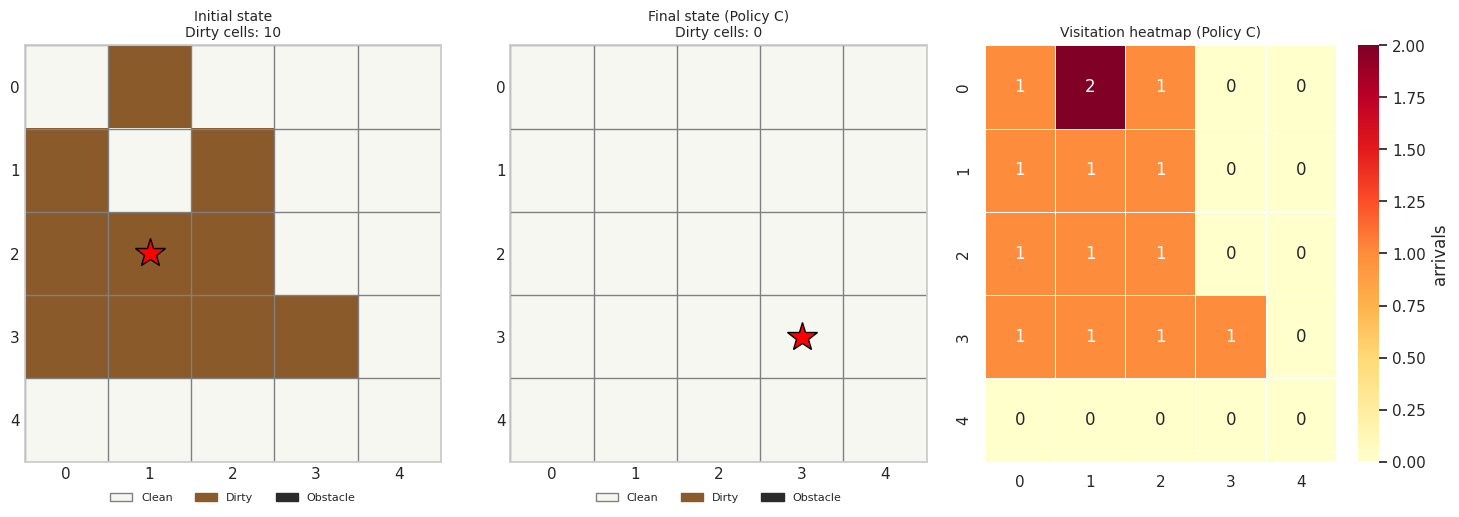

Steps: 23 | Success: True | Efficiency: 43.5%


,step,position,action,outcome,remaining_dirt
0,1,"(2, 1)",SUCK,CLEANED,9
1,2,"(3, 1)",DOWN,MOVED,9
2,3,"(3, 1)",SUCK,CLEANED,8
3,4,"(3, 0)",LEFT,MOVED,8
4,5,"(3, 0)",SUCK,CLEANED,7
5,6,"(2, 0)",UP,MOVED,7
6,7,"(2, 0)",SUCK,CLEANED,6
7,8,"(1, 0)",UP,MOVED,6
8,9,"(1, 0)",SUCK,CLEANED,5
9,10,"(1, 1)",RIGHT,MOVED,5


In [5]:
_CMAP = ListedColormap(["#f7f7f2", "#8b5a2b", "#2b2b2b"])   # clean, dirty, obstacle


def plot_grid(room, title="Room", ax=None, show=True, show_initial=False, figsize=(5, 5)):
    """Draw the room. show_initial=True draws the starting layout and start position."""
    created = ax is None
    if created:
        _, ax = plt.subplots(figsize=figsize)

    grid = room.initial_grid if show_initial else room.grid
    pos = room.start_pos if show_initial else room.agent_pos

    ax.imshow(grid, cmap=_CMAP, vmin=0, vmax=2)
    ax.grid(False)
    ax.set_xticks(range(room.cols))
    ax.set_yticks(range(room.rows))
    ax.set_xticks(np.arange(-0.5, room.cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, room.rows, 1), minor=True)
    ax.grid(True, which="minor", color="gray", linewidth=1)
    ax.tick_params(which="both", length=0)

    ax.plot(pos[1], pos[0], marker="*", color="red", markersize=22,
            markeredgecolor="black", linestyle="None")
    ax.set_title(f"{title}\nDirty cells: {int((grid == DIRTY).sum())}", fontsize=10)
    ax.legend(handles=[Patch(color="#f7f7f2", ec="gray", label="Clean"),
                       Patch(color="#8b5a2b", label="Dirty"),
                       Patch(color="#2b2b2b", label="Obstacle")],
              loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=3, fontsize=8, frameon=False)
    if created and show:
        plt.tight_layout()
        plt.show()


def plot_visitation_heatmap(result, title="Visitation heatmap", ax=None, show=True, figsize=(5, 5)):
    """Heatmap of arrivals per cell (obstacles masked)."""
    created = ax is None
    if created:
        _, ax = plt.subplots(figsize=figsize)
    room = result["room"]
    sns.heatmap(result["visits"].astype(float), mask=(room.grid == OBSTACLE), annot=True,
                fmt=".0f", cmap="YlOrRd", linewidths=0.5, linecolor="white",
                cbar_kws={"label": "arrivals"}, ax=ax)
    ax.set_title(title, fontsize=10)
    if created and show:
        plt.tight_layout()
        plt.show()


# ---- Demo: initial grid, final grid, heatmap for one run ----
demo_room = Room(5, 5, 0.4, seed=7)
demo_agent = ReflexVacuumAgent("C", seed=7)
demo = simulate(demo_room, demo_agent)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plot_grid(demo_room, "Initial state", ax=axes[0], show_initial=True)
plot_grid(demo_room, "Final state (Policy C)", ax=axes[1])
plot_visitation_heatmap(demo, "Visitation heatmap (Policy C)", ax=axes[2])
plt.tight_layout()
plt.show()

print(f"Steps: {demo['total_steps']} | Success: {demo['success']} | Efficiency: {demo['efficiency']:.1f}%")
display(demo["trace_df"].head(10))

In [6]:
POLICY_NAMES = {"A": "A: Greedy-Adjacent", "B": "B: Random Walk", "C": "C: Memory-Based"}
SEEDS = list(range(15))

SCENARIOS = {
    "Sparse (20%)":    dict(rows=5,  cols=5,  dirt_ratio=0.20, obstacle_ratio=0.0),
    "Medium (40%)":    dict(rows=5,  cols=5,  dirt_ratio=0.40, obstacle_ratio=0.0),
    "Dense (70%)":     dict(rows=5,  cols=5,  dirt_ratio=0.70, obstacle_ratio=0.0),
    "Large 10x10":     dict(rows=10, cols=10, dirt_ratio=0.40, obstacle_ratio=0.0),
    "Small 3x3":       dict(rows=3,  cols=3,  dirt_ratio=0.40, obstacle_ratio=0.0),
    "Obstacles (20%)": dict(rows=5,  cols=5,  dirt_ratio=0.40, obstacle_ratio=0.20),
}


def run_experiments(scenarios=SCENARIOS, policies=("A", "B", "C"), seeds=SEEDS):
    rows_out = []
    for sc_name, params in scenarios.items():
        for seed in seeds:
            for pol in policies:
                room = Room(seed=seed, **params)          # same room for every policy
                agent = ReflexVacuumAgent(pol, seed=seed)
                res = simulate(room, agent)
                rows_out.append({
                    "Scenario": sc_name, "Policy": POLICY_NAMES[pol], "Seed": seed,
                    "dirt_ratio": params["dirt_ratio"], "rows": params["rows"], "cols": params["cols"],
                    "cells": params["rows"] * params["cols"],
                    "Steps": res["total_steps"], "Success": res["success"],
                    "Efficiency": res["efficiency"], "Wasted": res["wasted_actions"],
                    "Moves": res["moves"], "Revisits": res["revisits"], "Bumps": res["bumps"],
                    "Initial_Dirt": res["initial_dirt"], "Cleaned": res["cleaned_cells"],
                })
    return pd.DataFrame(rows_out)


raw = run_experiments()

summary = (raw.groupby(["Scenario", "Policy"], sort=False)
           .agg(Avg_Steps=("Steps", "mean"),
                Std_Dev=("Steps", "std"),
                Success_Rate=("Success", lambda s: 100 * s.mean()),
                Avg_Efficiency=("Efficiency", "mean"),
                Avg_Wasted=("Wasted", "mean"),
                Avg_Revisits=("Revisits", "mean"))
           .round(2).reset_index())
summary.columns = ["Scenario", "Policy", "Avg Steps", "Std Dev", "Success Rate (%)",
                   "Avg Efficiency (%)", "Avg Wasted Actions", "Avg Revisits"]

print(f"Total runs: {len(raw)}")
display(summary)

Total runs: 270


,Scenario,Policy,Avg Steps,Std Dev,Success Rate (%),Avg Efficiency (%),Avg Wasted Actions,Avg Revisits
0,Sparse (20%),A: Greedy-Adjacent,625.00,0.00,0.00,0.23,623.53,620.20
1,Sparse (20%),B: Random Walk,142.80,87.53,100.00,4.83,137.80,116.33
2,Sparse (20%),C: Memory-Based,20.53,6.29,100.00,26.38,15.53,1.47
3,Medium (40%),A: Greedy-Adjacent,584.73,155.95,6.67,3.93,579.33,572.53
4,Medium (40%),B: Random Walk,176.07,78.74,100.00,6.54,166.07,142.60
5,Medium (40%),C: Memory-Based,31.33,6.42,100.00,33.07,21.33,3.33
6,Dense (70%),A: Greedy-Adjacent,625.00,0.00,0.00,1.87,613.33,600.73
7,Dense (70%),B: Random Walk,174.80,76.65,100.00,12.04,156.80,133.40
8,Dense (70%),C: Memory-Based,46.47,7.54,100.00,39.57,28.47,6.13
9,Large 10x10,A: Greedy-Adjacent,2500.00,0.00,0.00,0.31,2492.13,2482.00


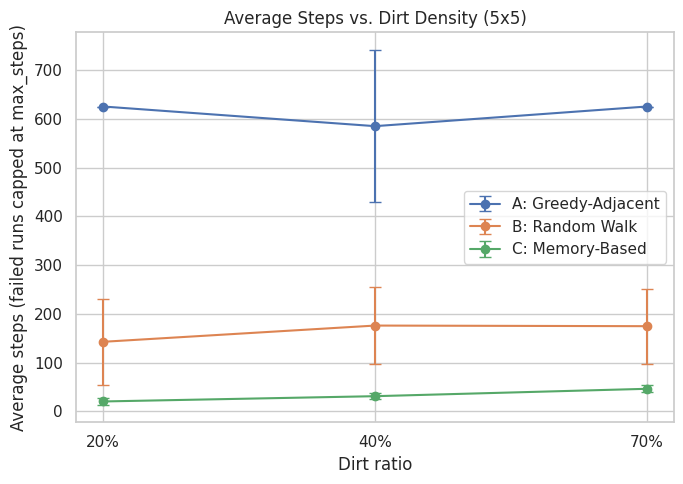

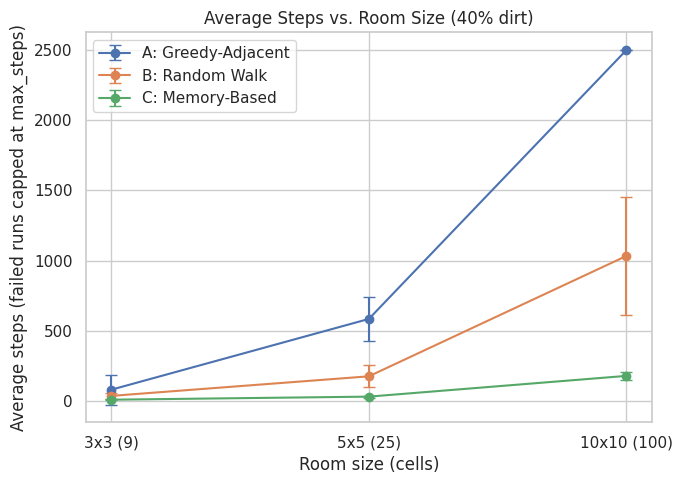

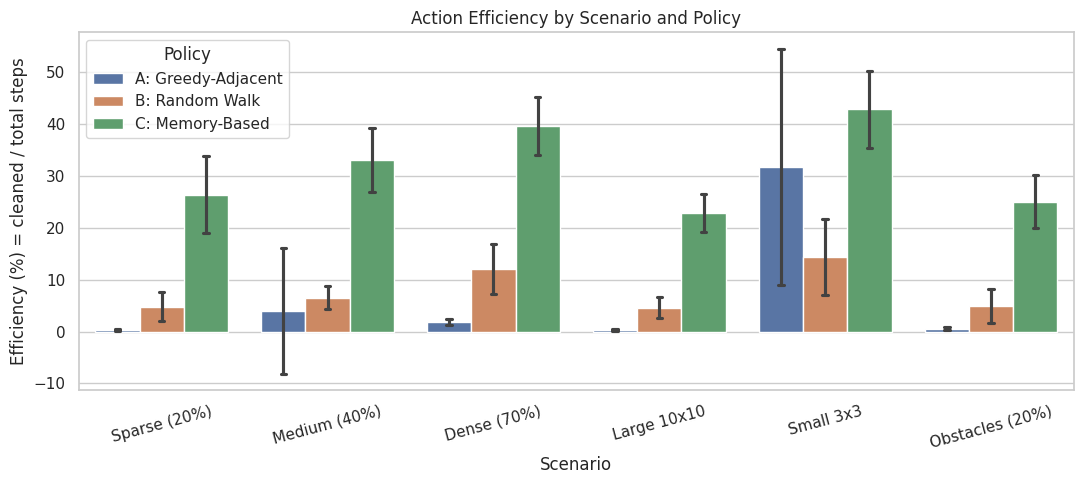

In [8]:
def _line_plot(ax, scenario_order, x_labels, title, xlabel):
    sub = raw[raw["Scenario"].isin(scenario_order)]
    stats = sub.groupby(["Policy", "Scenario"])["Steps"].agg(["mean", "std"]).reset_index()
    for pol in POLICY_NAMES.values():
        s = stats[stats["Policy"] == pol].set_index("Scenario").loc[scenario_order]
        ax.errorbar(range(len(scenario_order)), s["mean"], yerr=s["std"],
                    marker="o", capsize=4, label=pol)
    ax.set_xticks(range(len(scenario_order)))
    ax.set_xticklabels(x_labels)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Average steps (failed runs capped at max_steps)")
    ax.set_title(title)
    ax.legend()


# Plot 1: steps vs. dirt density
fig, ax = plt.subplots(figsize=(7, 5))
_line_plot(ax, ["Sparse (20%)", "Medium (40%)", "Dense (70%)"],
           ["20%", "40%", "70%"], "Average Steps vs. Dirt Density (5x5)", "Dirt ratio")
plt.tight_layout()
plt.show()

# Plot 2: steps vs. room size
fig, ax = plt.subplots(figsize=(7, 5))
_line_plot(ax, ["Small 3x3", "Medium (40%)", "Large 10x10"],
           ["3x3 (9)", "5x5 (25)", "10x10 (100)"], "Average Steps vs. Room Size (40% dirt)",
           "Room size (cells)")
plt.tight_layout()
plt.show()

# Plot 3 (bonus): efficiency per scenario
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=raw, x="Scenario", y="Efficiency", hue="Policy", errorbar="sd", capsize=0.1, ax=ax)
ax.set_ylabel("Efficiency (%) = cleaned / total steps")
ax.set_title("Action Efficiency by Scenario and Policy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

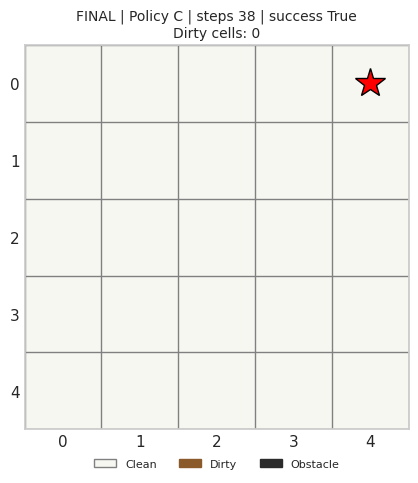

In [13]:
def animate_cleaning(policy="C", rows=5, cols=5, dirt_ratio=0.4, obstacle_ratio=0.0,
                     seed=1, delay=0.4, max_frames=60):
    room = Room(rows, cols, dirt_ratio, obstacle_ratio, seed=seed)
    agent = ReflexVacuumAgent(policy, seed=seed)

    def draw(room, step, action, outcome):
        clear_output(wait=True)
        plot_grid(room, title=f"Policy {policy} | step {step} | {action} -> {outcome}\n"
                              f"Dirt left: {room.get_remaining_dirt()}")
        time.sleep(delay)

    res = simulate(room, agent, max_steps=max_frames, callback=draw)
    clear_output(wait=True)
    plot_grid(room, title=f"FINAL | Policy {policy} | steps {res['total_steps']} | success {res['success']}")
    return res


_ = animate_cleaning(policy="C", rows=5, cols=5, dirt_ratio=0.4, seed=3, delay=0.3)